# What Drives Amazon Product Ratings?
### An end-to-end data analysis project in Python

**Author:** Gabriel Kanife

**Data:** [Amazon Sales Dataset (Kaggle)](https://www.kaggle.com/datasets/karkavelrajaj/amazon-sales-dataset): 1,465 product listings from Amazon India, with prices, discounts, ratings and customer reviews.

**Questions this project answers:**
1. What does the product catalog look like (categories, prices, discounts)?
2. Do bigger discounts go with better or worse ratings?
3. Can we **predict a product's rating** from its price, discount, popularity and category? Which factors matter most?

**Skills shown:** data cleaning, feature engineering, exploratory data analysis (EDA), data visualization, machine learning (regression), model evaluation.

---

## 1. Setup
We load the libraries we need:
- **pandas / numpy**: work with tables and numbers
- **matplotlib / seaborn**: make charts
- **scikit-learn**: build and evaluate machine learning models

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

# ---- One consistent chart style for the whole project ----
INK, INK_SOFT, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # colorblind-safe trio

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "font.size": 11, "figure.dpi": 110, "savefig.dpi": 200,
    "savefig.bbox": "tight",
})

CHARTS = Path("charts"); CHARTS.mkdir(exist_ok=True)
RANDOM_STATE = 42   # fixes the randomness so results are reproducible

## 2. Load the data and take a first look
Always start by checking the shape, column types and a few rows before doing anything else.

In [2]:
raw = pd.read_csv("amazon.csv")
print("Rows, columns:", raw.shape)
raw.head(3)

Rows, columns: (1465, 16)


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...


In [3]:
# Every column was read as text (str), including prices and ratings.
# That tells us cleaning is needed before we can do any math.
raw.dtypes

product_id             str
product_name           str
category               str
discounted_price       str
actual_price           str
discount_percentage    str
rating                 str
rating_count           str
about_product          str
user_id                str
user_name              str
review_id              str
review_title           str
review_content         str
img_link               str
product_link           str
dtype: object

In [4]:
# Peek at the messy number columns
raw[["discounted_price", "actual_price", "discount_percentage", "rating", "rating_count"]].sample(5, random_state=1)

,discounted_price,actual_price,discount_percentage,rating,rating_count
1005,₹225,₹225,0%,4.1,"4,798"
653,₹129,₹999,87%,4.2,491
623,₹199,₹999,80%,3.9,"7,928"
919,₹272,₹320,15%,4.0,"3,686"
859,"₹1,599","₹3,490",54%,3.7,676


## 3. Data cleaning
Problems found in the first look:

| Column | Problem | Fix |
|---|---|---|
| `discounted_price`, `actual_price` | Text like `"₹1,099"` | Remove `₹` and commas, convert to number |
| `discount_percentage` | Text like `"64%"` | Remove `%`, convert to number |
| `rating_count` | Text like `"24,269"`, 2 missing | Remove commas, convert to number, drop the missing rows |
| `rating` | One row has `"|"` instead of a number | Convert to number; the bad value becomes missing and is dropped |
| `product_id` | Some products appear more than once | Keep one row per product |
| `category` | A long path like `Electronics|Mobiles|...` | Split into a main category and a sub-category |

In [5]:
df = raw.copy()

def to_number(series):
    """Strip currency symbols, commas and % signs, then convert to a number.
    Anything that still can't be converted becomes NaN (missing)."""
    cleaned = series.astype(str).str.replace(r"[₹,%]", "", regex=True).str.strip()
    return pd.to_numeric(cleaned, errors="coerce")

for col in ["discounted_price", "actual_price", "discount_percentage", "rating", "rating_count"]:
    df[col] = to_number(df[col])

# How many values could not be converted?
df[["discounted_price", "actual_price", "discount_percentage", "rating", "rating_count"]].isna().sum()

discounted_price       0
actual_price           0
discount_percentage    0
rating                 1
rating_count           2
dtype: int64

In [6]:
before = len(df)

# Drop rows where the key numbers are missing
df = df.dropna(subset=["rating", "rating_count"])

# Keep one row per product (duplicates are the same product listed again)
df = df.drop_duplicates(subset="product_id", keep="first")

# Split the category path: "Electronics|Mobiles&Accessories|..."
cat_parts = df["category"].str.split("|")
df["main_category"] = cat_parts.str[0]
df["sub_category"] = cat_parts.str[-1]          # the most specific level

print(f"Rows before: {before:,}  ->  after cleaning: {len(df):,}")
df[["product_name", "main_category", "sub_category", "actual_price", "discounted_price",
    "discount_percentage", "rating", "rating_count"]].head()

Rows before: 1,465  ->  after cleaning: 1,348


,product_name,main_category,sub_category,actual_price,discounted_price,discount_percentage,rating,rating_count
0,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories,USBCables,1099.0,399.0,64,4.2,24269.0
1,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories,USBCables,349.0,199.0,43,4.0,43994.0
2,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories,USBCables,1899.0,199.0,90,3.9,7928.0
3,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories,USBCables,699.0,329.0,53,4.2,94363.0
4,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories,USBCables,399.0,154.0,61,4.2,16905.0


In [7]:
# Make category names easier to read:
# "Home&Kitchen" -> "Home & Kitchen", "OfficeProducts" -> "Office Products"
def tidy(name):
    return (name.str.replace("&", " & ", regex=False)
                .str.replace(r"(?<=[a-z])(?=[A-Z])", " ", regex=True))
df["main_category"] = tidy(df["main_category"])
df["sub_category"] = tidy(df["sub_category"])
df["main_category"].value_counts()

main_category
Electronics                490
Home & Kitchen             447
Computers & Accessories    373
Office Products             31
Musical Instruments          2
Home Improvement             2
Toys & Games                 1
Car & Motorbike              1
Health & Personal Care       1
Name: count, dtype: int64

Three categories make up almost the whole catalog. The tiny ones (Office Products and the categories with 1 or 2 items) are grouped into **"Other"** so they don't distort comparisons.

In [8]:
top3 = ["Electronics", "Computers & Accessories", "Home & Kitchen"]
df["category_group"] = np.where(df["main_category"].isin(top3), df["main_category"], "Other")
df["category_group"].value_counts()

category_group
Electronics                490
Home & Kitchen             447
Computers & Accessories    373
Other                       38
Name: count, dtype: int64

### Feature engineering
New columns that may help explain ratings:
- `savings`: rupees saved (actual price minus discounted price)
- `log_rating_count`: the number of ratings ranges from 2 to over 400,000. Taking the log squeezes that range so a few very popular products don't dominate.
- `log_actual_price`: same idea for price
- `discount_band`: discounts grouped into easy-to-read bands

In [9]:
df["savings"] = df["actual_price"] - df["discounted_price"]
df["log_rating_count"] = np.log10(df["rating_count"])
df["log_actual_price"] = np.log10(df["actual_price"])
df["discount_band"] = pd.cut(df["discount_percentage"], bins=[-1, 20, 40, 60, 80, 100],
                             labels=["0-20%", "21-40%", "41-60%", "61-80%", "81-100%"])

# Save the clean data so it can be reused (for example, in R later)
df.drop(columns=["img_link", "product_link"]).to_csv("amazon_clean.csv", index=False)
df[["actual_price", "discounted_price", "discount_percentage", "rating", "rating_count"]].describe().round(1)

,actual_price,discounted_price,discount_percentage,rating,rating_count
count,1348.0,1348.0,1348.0,1348.0,1348.0
mean,5700.5,3310.3,46.7,4.1,17656.8
std,11229.4,7180.9,21.6,0.3,42158.8
min,39.0,39.0,0.0,2.0,2.0
25%,899.0,349.0,31.0,3.9,1107.5
50%,1795.0,899.0,49.0,4.1,4740.0
75%,4592.5,2184.0,62.0,4.3,16051.5
max,139900.0,77990.0,94.0,5.0,426973.0


## 4. Exploratory data analysis (EDA)
### 4.1 How are ratings distributed?

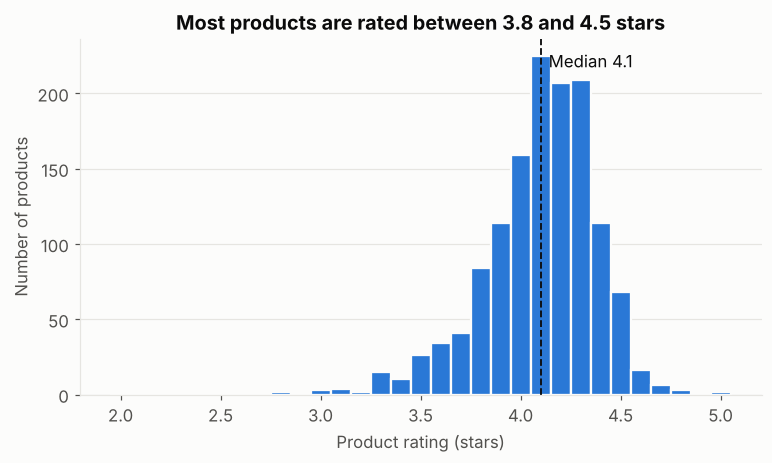

88% of products are rated between 3.8 and 4.5. Std. deviation: 0.30 stars


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.arange(1.95, 5.1, 0.1)
ax.hist(df["rating"], bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
med = df["rating"].median()
ax.axvline(med, color=INK, linestyle="--", linewidth=1.2)
ax.text(med + 0.04, ax.get_ylim()[1] * 0.92, f"Median {med:.1f}", color=INK)
ax.set_title("Most products are rated between 3.8 and 4.5 stars")
ax.set_xlabel("Product rating (stars)"); ax.set_ylabel("Number of products")
ax.grid(axis="x", visible=False)
fig.savefig(CHARTS / "01_rating_distribution.png")
plt.show()

share = df["rating"].between(3.8, 4.5).mean()
print(f"{share:.0%} of products are rated between 3.8 and 4.5. Std. deviation: {df['rating'].std():.2f} stars")

**Why this matters:** ratings are squeezed into a narrow band. When almost everything is rated around 4.1, there is not much variation left for any factor to explain. Keep this in mind for the model in Section 5.

### 4.2 Price and discount by category

In [11]:
summary = (df.groupby("category_group")
             .agg(products=("product_id", "count"),
                  median_price=("actual_price", "median"),
                  avg_discount=("discount_percentage", "mean"),
                  avg_rating=("rating", "mean"))
             .sort_values("products", ascending=False)
             .round(2))
summary

,products,median_price,avg_discount,avg_rating
category_group,,,,
Electronics,490,2999.0,49.91,4.08
Home & Kitchen,447,2000.0,40.17,4.04
Computers & Accessories,373,999.0,53.09,4.15
Other,38,275.0,18.03,4.26


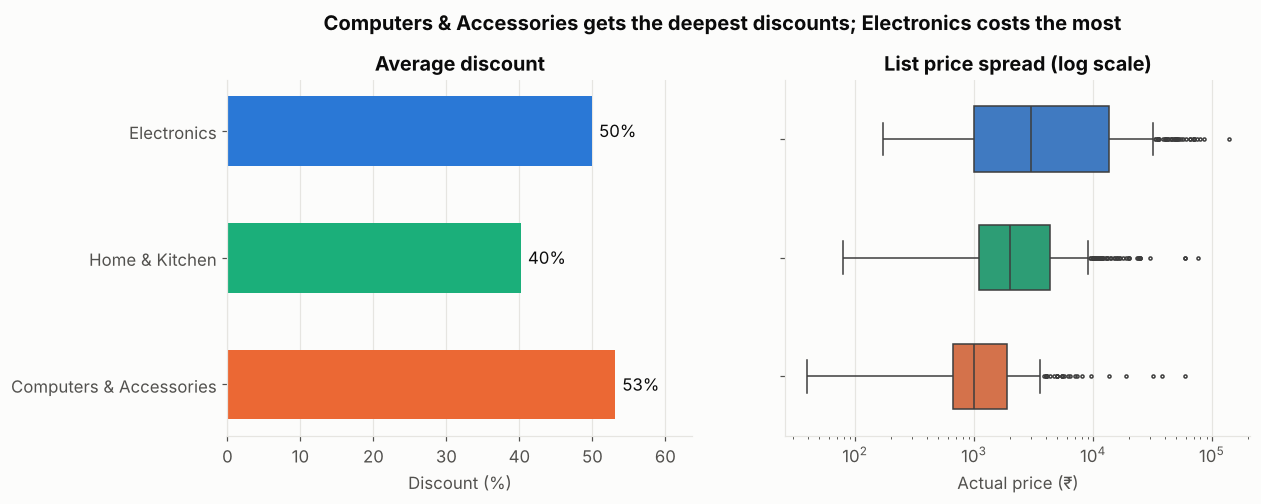

In [12]:
order = summary.index.drop("Other")          # focus on the 3 main categories
colors = {"Electronics": BLUE, "Computers & Accessories": ORANGE, "Home & Kitchen": AQUA}
main = df[df["category_group"].isin(order)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
# Left: average discount
vals = summary.loc[order, "avg_discount"]
axes[0].barh(order, vals, color=[colors[c] for c in order], height=0.55)
for i, v in enumerate(vals):
    axes[0].text(v + 1, i, f"{v:.0f}%", va="center", color=INK)
axes[0].invert_yaxis(); axes[0].set_xlim(0, vals.max() * 1.2)
axes[0].set_title("Average discount"); axes[0].set_xlabel("Discount (%)")
axes[0].grid(axis="y", visible=False)

# Right: price spread (log scale because prices range from ₹39 to ₹140,000)
sns.boxplot(data=main, y="category_group", x="actual_price", order=order, hue="category_group",
            palette=colors, ax=axes[1], width=0.55, fliersize=2, legend=False)
axes[1].set_xscale("log"); axes[1].set_ylabel(""); axes[1].set_yticklabels([])
axes[1].set_title("List price spread (log scale)"); axes[1].set_xlabel("Actual price (₹)")
axes[1].grid(axis="y", visible=False)
fig.suptitle("Computers & Accessories gets the deepest discounts; Electronics costs the most",
             fontweight="bold", color=INK, y=1.03)
fig.savefig(CHARTS / "02_category_price_discount.png")
plt.show()

### 4.3 Do bigger discounts mean better or worse ratings?

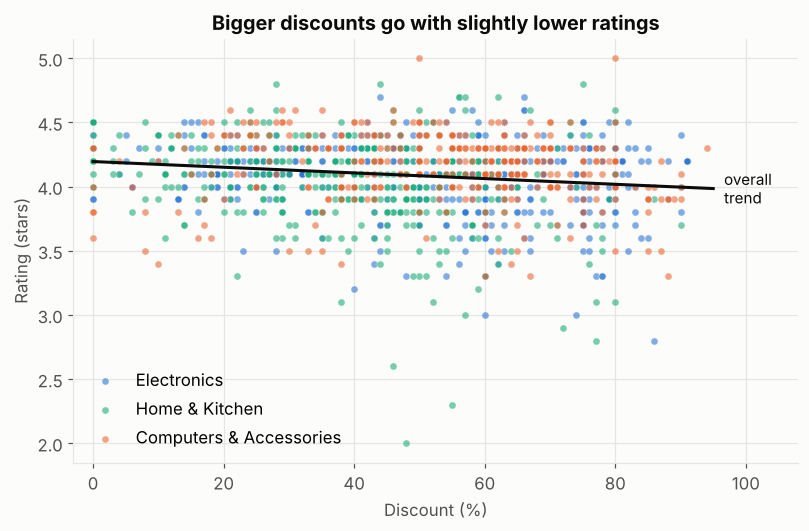

Correlation between discount and rating: r = -0.16
Trend: every +10 points of discount is linked to -0.022 stars


In [13]:
fig, ax = plt.subplots(figsize=(8.5, 5))
for cat in order:
    sub = main[main["category_group"] == cat]
    ax.scatter(sub["discount_percentage"], sub["rating"], s=22, alpha=0.6,
               color=colors[cat], label=cat, edgecolor=SURFACE, linewidth=0.5)
# Overall trend line (simple linear fit)
m, b = np.polyfit(df["discount_percentage"], df["rating"], 1)
xs = np.linspace(0, 95, 50)
ax.plot(xs, m * xs + b, color=INK, linewidth=2)
ax.text(96, m * 95 + b, " overall\n trend", color=INK, va="center", fontsize=10)
ax.set_xlim(-3, 108)
ax.set_title("Bigger discounts go with slightly lower ratings")
ax.set_xlabel("Discount (%)"); ax.set_ylabel("Rating (stars)")
ax.legend(frameon=False, loc="lower left")
fig.savefig(CHARTS / "03_discount_vs_rating.png")
plt.show()

r = df["discount_percentage"].corr(df["rating"])
print(f"Correlation between discount and rating: r = {r:.2f}")
print(f"Trend: every +10 points of discount is linked to {m*10:+.3f} stars")

In [14]:
band = (df.groupby("discount_band", observed=True)
          .agg(products=("rating", "size"), avg_rating=("rating", "mean"),
               pct_4_or_more=("rating", lambda s: (s >= 4.0).mean() * 100))
          .round(2))
band

,products,avg_rating,pct_4_or_more
discount_band,,,
0-20%,175,4.17,83.43
21-40%,329,4.13,80.24
41-60%,469,4.07,71.64
61-80%,324,4.07,72.22
81-100%,51,3.97,56.86


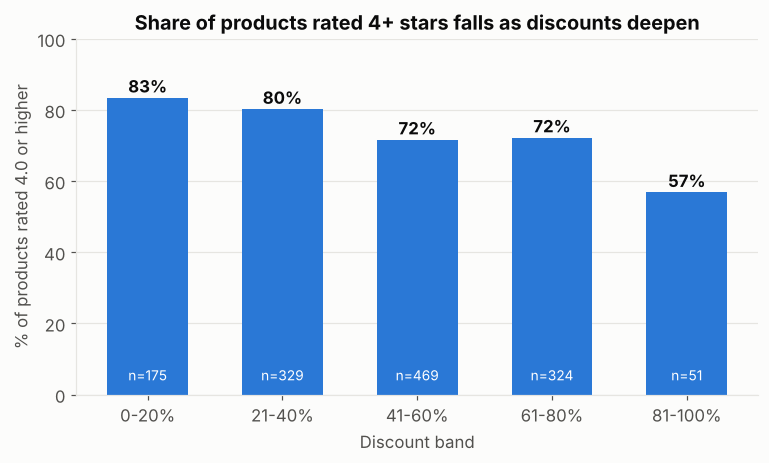

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(band.index.astype(str), band["pct_4_or_more"], color=BLUE, width=0.6)
for i, (v, n) in enumerate(zip(band["pct_4_or_more"], band["products"])):
    ax.text(i, v + 1.5, f"{v:.0f}%", ha="center", color=INK, fontweight="bold")
    ax.text(i, 4, f"n={n}", ha="center", color="white", fontsize=9)
ax.set_ylim(0, 100)
ax.set_title("Share of products rated 4+ stars falls as discounts deepen")
ax.set_xlabel("Discount band"); ax.set_ylabel("% of products rated 4.0 or higher")
ax.grid(axis="x", visible=False)
fig.savefig(CHARTS / "04_discount_band_share_4plus.png")
plt.show()

### 4.4 How do the numeric columns relate to each other?
A correlation of +1 means two columns rise together, −1 means one rises as the other falls, and 0 means no straight-line relationship.

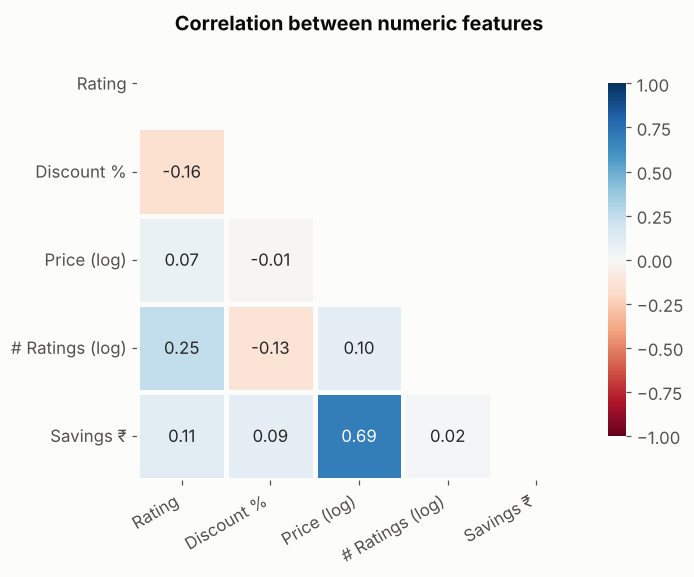

In [16]:
num_cols = ["rating", "discount_percentage", "log_actual_price", "log_rating_count", "savings"]
labels = ["Rating", "Discount %", "Price (log)", "# Ratings (log)", "Savings ₹"]
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))   # hide the duplicate upper half and the 1.00 diagonal

fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu", vmin=-1, vmax=1, center=0,
            xticklabels=labels, yticklabels=labels, linewidths=2, linecolor=SURFACE,
            cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation between numeric features"); ax.grid(False)
plt.xticks(rotation=30, ha="right")
fig.savefig(CHARTS / "05_correlation_heatmap.png")
plt.show()

## 5. Predicting a product's rating (machine learning)
**Goal:** given a product's price, discount, popularity and category, predict its star rating.

**Approach:**
1. Split the data: 80% to **train** the models, 20% held back to **test** them on products they have never seen.
2. Compare three models:
   - **Baseline**: always guesses the average rating. Any real model has to beat this.
   - **Linear Regression**: a simple, easy-to-explain model.
   - **Random Forest**: many decision trees averaged together; can capture non-linear patterns.
3. Measure with **MAE** (average error in stars; lower is better) and **R²** (share of the variation in ratings the model explains; higher is better).

In [17]:
# Sub-categories with at least 15 products get their own column; the rest go to "Other"
top_subs = df["sub_category"].value_counts()
top_subs = top_subs[top_subs >= 15].index
df["sub_group"] = np.where(df["sub_category"].isin(top_subs), df["sub_category"], "Other")

numeric_features = ["log_actual_price", "discount_percentage", "log_rating_count"]
X = pd.get_dummies(df[numeric_features + ["category_group", "sub_group"]],
                   columns=["category_group", "sub_group"], drop_first=True, dtype=int)
y = df["rating"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Features: {X.shape[1]}  |  Train: {len(X_train)}  |  Test: {len(X_test)}")

Features: 23  |  Train: 1078  |  Test: 270


In [18]:
models = {
    "Baseline (always predict mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=5,
                                           random_state=RANDOM_STATE, n_jobs=-1),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    # Cross-validation: train/test 5 times on different splits for a more reliable score
    cv_r2 = cross_val_score(model, X, y, cv=cv, scoring="r2").mean()
    rows.append({"Model": name,
                 "Test MAE (stars)": mean_absolute_error(y_test, pred),
                 "Test R²": r2_score(y_test, pred),
                 "5-fold CV R²": cv_r2})

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Test MAE (stars),Test R²,5-fold CV R²
Model,,,
Baseline (always predict mean),0.230,-0.005,-0.003
Linear Regression,0.203,0.177,0.162
Random Forest,0.202,0.153,0.171


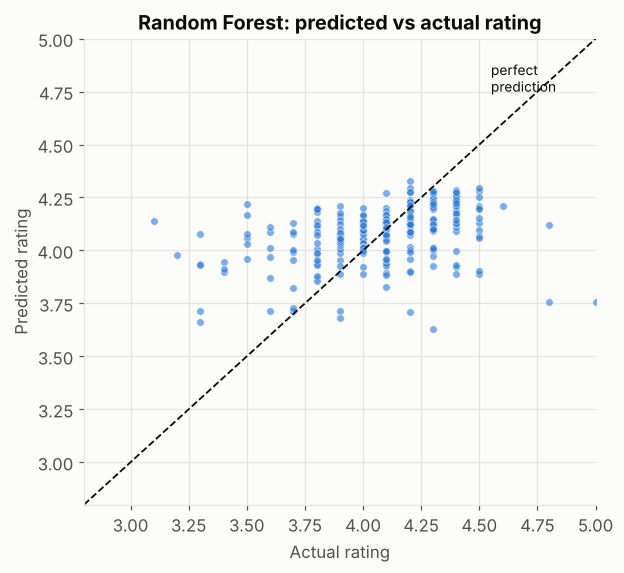

In [19]:
rf = models["Random Forest"]
rf_pred = rf.predict(X_test)

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(y_test, rf_pred, s=24, alpha=0.6, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
lims = [2.8, 5.0]
ax.plot(lims, lims, color=INK, linestyle="--", linewidth=1.2)
ax.text(4.55, 4.75, "perfect\nprediction", color=INK, fontsize=9)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_title("Random Forest: predicted vs actual rating")
ax.set_xlabel("Actual rating"); ax.set_ylabel("Predicted rating")
fig.savefig(CHARTS / "06_predicted_vs_actual.png")
plt.show()

### Which features matter most?
**Permutation importance** shuffles one feature at a time and measures how much worse the model gets. A big drop means the model relies on that feature.

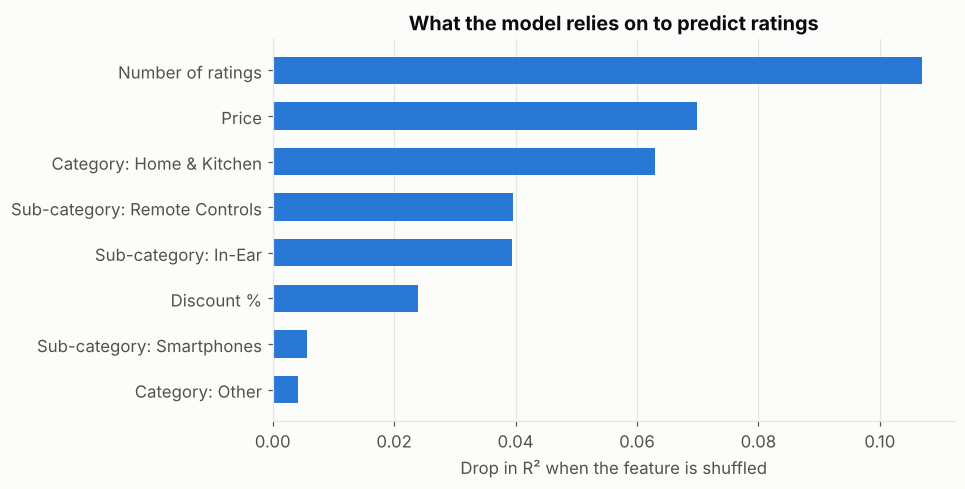

log_rating_count                 0.1070
log_actual_price                 0.0699
category_group_Home & Kitchen    0.0630
sub_group_Remote Controls        0.0397
sub_group_In-Ear                 0.0394
discount_percentage              0.0238
sub_group_Smartphones            0.0057
category_group_Other             0.0042
dtype: float64

In [20]:
perm = permutation_importance(rf, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.Series(perm.importances_mean, index=X_test.columns)
         .sort_values(ascending=False))

# Readable names for the chart
nice = {"log_rating_count": "Number of ratings", "discount_percentage": "Discount %",
        "log_actual_price": "Price"}
top = imp.head(8).rename(lambda c: nice.get(c, c.replace("sub_group_", "Sub-category: ")
                                              .replace("category_group_", "Category: ")))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index[::-1], top.values[::-1], color=BLUE, height=0.6)
ax.set_title("What the model relies on to predict ratings")
ax.set_xlabel("Drop in R² when the feature is shuffled")
ax.grid(axis="y", visible=False)
fig.savefig(CHARTS / "07_feature_importance.png")
plt.show()
imp.head(8).round(4)

In [21]:
# The linear model's coefficients show the DIRECTION of each effect
lin = models["Linear Regression"]
coefs = pd.Series(lin.coef_, index=X.columns)[numeric_features].rename(nice)
print("Linear regression effects (holding other features constant):")
print(f"  10x more ratings      -> {coefs['Number of ratings']:+.3f} stars")
print(f"  +10 points of discount -> {coefs['Discount %']*10:+.3f} stars")
print(f"  10x higher price      -> {coefs['Price']:+.3f} stars")

Linear regression effects (holding other features constant):
  10x more ratings      -> +0.062 stars
  +10 points of discount -> -0.023 stars
  10x higher price      -> +0.124 stars


## 6. Key findings
1. **Ratings are tightly clustered.** 88% of products sit between 3.8 and 4.5 stars (standard deviation 0.30). A "4.1" on Amazon is average, not good.
2. **Deeper discounts go with lower ratings.** 83% of products with a 0–20% discount are rated 4+ stars, compared with just 57% of products discounted more than 80%. The overall relationship is weak (r = −0.16), but the pattern holds across discount bands.
3. **Ratings are hard to predict from listing data alone.** The best models explain about **16–17%** of the variation in ratings (5-fold CV R²) and cut the average error from 0.23 to 0.20 stars compared with guessing the mean. Most of what makes a product well rated (its actual quality) is not in these columns.
4. **Popularity and price matter most.** The number of ratings is the strongest predictor, followed by price and category. Products with more ratings and higher prices tend to score slightly higher, and Home & Kitchen products rate lowest on average.
5. **The simple model is as good as the complex one.** Linear Regression performs about the same as Random Forest, so the relationships are mostly simple, and the easier-to-explain model is the better choice here.

## 7. Limitations and next steps
- **No time or sales data.** The dataset is a single snapshot, so it cannot show trends or support sales forecasting.
- **Amazon India only, about 1,350 products, mostly in 3 categories.** The results may not hold for other markets or categories.
- **Correlation is not causation.** Deep discounts may go with lower ratings because cheaper, lower-quality products are discounted more, not because discounts *cause* bad reviews.
- **Next steps:**
  - Sentiment analysis of `review_content` to see whether review text adds predictive power
  - A content-based recommendation system using `about_product`
  - Recreate the key charts in R with ggplot2 using `amazon_clean.csv`